# Homework 6.2 - Steps 3-6

## Attention Decoder, Matched Non-Attention Baseline, Evaluation, and Architecture Study

This notebook performs the main one-to-one glyph-decipherment experiment.

The input at target position $$i$$ is a **centered** glyph window

$$
g_{i-m},\ldots,g_i,\ldots,g_{i+m}.
$$

The output is

$$
P_\theta
\left(
t_i
\mid
g_{i-m},\ldots,g_i,\ldots,g_{i+m}
\right).
$$

Unlike Homework 6.1, this is not causal next-token prediction. The assignment explicitly permits both left and right context for decoding the center glyph, so the self-attention layer is bidirectional within the supplied window.

Two decoder families are trained under the same information regime:

1. a self-attention decoder;
2. a Chapter-5-style embedding-plus-MLP baseline.

Both use exactly the same carried-over Republic-informed pseudo-labels.

## Experimental safeguards

The training procedure follows these rules.

### Before final evaluation

Only the following are loaded:

- training glyph sequence;
- validation glyph sequence;
- revealed anchors;
- carried-over Republic-informed pseudo-label maps;
- common validation positions.

The test glyph sequence and hidden map are **not loaded** while architectures or checkpoints are being selected.

### Architecture selection

The architecture sweep uses the 20% anchor condition and validation pseudo-label cross-entropy.

This selection criterion measures how well the neural model learns the permitted Homework 5.1 pseudo-label target. It is not treated as evidence that the hidden decipherment is correct.

### Final comparison

After the architecture is frozen:

- attention and MLP models are trained separately at 5%, 10%, 20%, and 40% anchors;
- the same pseudo-label map is used for both decoders at each anchor level;
- both models use the same centered context radius;
- both are evaluated on the same test center positions;
- only then is the evaluation-only true map opened.

In [1]:
from pathlib import Path
import json
import math
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_2"
MODEL_DIR = DATA_DIR / "models"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    DATA_DIR
    / "task2_frozen_information_manifest.json"
)

if not manifest_path.exists():
    raise FileNotFoundError(
        "Run HW6.2 Step 2 before this notebook."
    )

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)

ANCHOR_LEVELS = ["05", "10", "20", "40"]
K = int(
    manifest["source_vocabulary_size"]
)

SEED = 63862
BATCH_SIZE = 256
MAX_EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-5
DROPOUT = 0.10

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print("Source vocabulary size K:", K)

Device: cuda
Source vocabulary size K: 3052


# Load training and validation artifacts only

The test split and true hidden map are deliberately absent from this section.

In [2]:
def absolute_from_manifest(relative_path):
    return PROJECT_ROOT / relative_path


def pick_column(frame, candidates, label):
    lowered = {
        column.lower(): column
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lowered:
            return lowered[candidate.lower()]

    for column in frame.columns:
        low = column.lower()

        if any(
            candidate.lower() in low
            for candidate in candidates
        ):
            return column

    raise KeyError(
        f"Could not identify {label}. "
        f"Available columns: {list(frame.columns)}"
    )


GLYPH_CANDIDATES = [
    "glyph_id",
    "glyph",
    "glyph_index",
    "token",
]

SOURCE_CANDIDATES = [
    "source_token_id",
    "syllable_id",
    "source_id",
    "token_id",
]


def load_glyph_sequence(split_name):
    path = absolute_from_manifest(
        manifest["splits"][
            split_name
        ]
    )

    frame = pd.read_csv(path)

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    return frame[
        glyph_col
    ].to_numpy()


def load_anchor(level):
    path = absolute_from_manifest(
        manifest["anchors"][level]
    )

    frame = pd.read_csv(path)

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    source_col = pick_column(
        frame,
        SOURCE_CANDIDATES,
        "source-token ID",
    )

    normalized = frame[
        [
            glyph_col,
            source_col,
        ]
    ].copy()

    normalized.columns = [
        "glyph_id",
        "source_token_id",
    ]

    return normalized


def load_pseudo_map(level):
    path = absolute_from_manifest(
        manifest[
            "pseudo_label_maps"
        ][level]
    )

    frame = pd.read_csv(path)

    if set(
        [
            "glyph_id",
            "source_token_id",
        ]
    ) <= set(frame.columns):
        return frame[
            [
                "glyph_id",
                "source_token_id",
            ]
        ].copy()

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    source_col = pick_column(
        frame,
        SOURCE_CANDIDATES,
        "source-token ID",
    )

    normalized = frame[
        [
            glyph_col,
            source_col,
        ]
    ].copy()

    normalized.columns = [
        "glyph_id",
        "source_token_id",
    ]

    return normalized


train_raw = load_glyph_sequence(
    "train"
)

validation_raw = load_glyph_sequence(
    "validation"
)

anchors = {
    level: load_anchor(level)
    for level in ANCHOR_LEVELS
}

pseudo_maps = {
    level: load_pseudo_map(level)
    for level in ANCHOR_LEVELS
}

common_positions = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "common_evaluation_positions"
        ]
    )
)

validation_common_positions = (
    common_positions[
        common_positions["split"]
        == "validation"
    ]["position"]
    .to_numpy(dtype=int)
)

print("Training glyphs:", f"{len(train_raw):,}")
print("Validation glyphs:", f"{len(validation_raw):,}")
print(
    "Common validation centers:",
    f"{len(validation_common_positions):,}",
)
print()
print(
    "Test split and hidden map have not been loaded."
)

Training glyphs: 54,082
Validation glyphs: 11,589
Common validation centers: 11,557

Test split and hidden map have not been loaded.


## Normalize raw IDs for neural-network indexing

The carried-over IDs themselves are not changed in the saved data.

For PyTorch, raw glyph IDs and raw source-token IDs are mapped deterministically to contiguous indices

$$
0,\ldots,K-1.
$$

The raw-ID lookup tables are saved for later interpretation.

In [3]:
reference_pseudo = pseudo_maps["20"]

raw_glyph_ids = np.array(
    sorted(
        reference_pseudo[
            "glyph_id"
        ].unique()
    )
)

raw_source_ids = np.array(
    sorted(
        reference_pseudo[
            "source_token_id"
        ].unique()
    )
)

if len(raw_glyph_ids) != K:
    raise ValueError(
        "Glyph vocabulary size does not match K."
    )

if len(raw_source_ids) != K:
    raise ValueError(
        "Source vocabulary size does not match K."
    )

glyph_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_glyph_ids)
}

index_to_glyph = {
    index: raw_id
    for raw_id, index
    in glyph_to_index.items()
}

source_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_source_ids)
}

index_to_source = {
    index: raw_id
    for raw_id, index
    in source_to_index.items()
}


def encode_glyphs(raw_sequence):
    try:
        return np.array(
            [
                glyph_to_index[value]
                for value in raw_sequence
            ],
            dtype=np.int64,
        )

    except KeyError as error:
        raise KeyError(
            f"Unknown raw glyph ID: {error}"
        )


def pseudo_label_indices(
    raw_sequence,
    level,
):
    mapping = dict(
        zip(
            pseudo_maps[level][
                "glyph_id"
            ],
            pseudo_maps[level][
                "source_token_id"
            ],
        )
    )

    return np.array(
        [
            source_to_index[
                mapping[glyph]
            ]
            for glyph
            in raw_sequence
        ],
        dtype=np.int64,
    )


train_glyphs = encode_glyphs(
    train_raw
)

validation_glyphs = encode_glyphs(
    validation_raw
)

train_labels = {
    level: pseudo_label_indices(
        train_raw,
        level,
    )
    for level in ANCHOR_LEVELS
}

validation_labels = {
    level: pseudo_label_indices(
        validation_raw,
        level,
    )
    for level in ANCHOR_LEVELS
}

lookup_frame = pd.DataFrame({
    "model_glyph_index": np.arange(K),
    "raw_glyph_id": raw_glyph_ids,
    "model_source_index": np.arange(K),
    "raw_source_token_id": raw_source_ids,
})

lookup_path = (
    DATA_DIR
    / "task3_id_lookup.csv"
)

lookup_frame.to_csv(
    lookup_path,
    index=False,
)

print("Saved:", lookup_path.resolve())

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\data\hw6_2\task3_id_lookup.csv


# Centered-window datasets

For context radius $$m$$, each training example has window length

$$
2m+1.
$$

The center position is included as an observed glyph because the task is to infer its original syllable identity from its glyph identity and surrounding context.

Training uses all valid centers for the selected radius.

Validation architecture comparisons use the common positions frozen in Step 2.

In [4]:
class CenteredWindowDataset(Dataset):
    def __init__(
        self,
        glyph_sequence,
        label_sequence,
        radius,
        centers=None,
    ):
        self.glyphs = np.asarray(
            glyph_sequence,
            dtype=np.int64,
        )

        self.labels = np.asarray(
            label_sequence,
            dtype=np.int64,
        )

        self.radius = int(radius)

        if centers is None:
            centers = np.arange(
                self.radius,
                len(self.glyphs)
                - self.radius,
                dtype=int,
            )

        centers = np.asarray(
            centers,
            dtype=int,
        )

        valid = (
            (centers >= self.radius)
            & (
                centers
                < len(self.glyphs)
                - self.radius
            )
        )

        self.centers = centers[
            valid
        ]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, item):
        center = int(
            self.centers[item]
        )

        start = center - self.radius
        stop = center + self.radius + 1

        window = self.glyphs[
            start:stop
        ]

        label = self.labels[
            center
        ]

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                int(label),
                dtype=torch.long,
            ),
            torch.tensor(
                center,
                dtype=torch.long,
            ),
        )

# Task 3: attention-based decoder

The decoder contains:

- glyph embeddings;
- learned positional information;
- one or more bidirectional self-attention layers;
- a center-position representation;
- a softmax classifier over the $$K=3052$$ source syllables.

For each layer,

$$
Q=HW_Q,\qquad
K=HW_K,\qquad
V=HW_V,
$$

and

$$
A
=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right).
$$

No causal mask is used because the assignment permits context on both sides of the target.

In [5]:
class AttentionBlock(nn.Module):
    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_multiplier,
        dropout,
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                ff_multiplier * embed_dim,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                ff_multiplier * embed_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_weights=False,
    ):
        attended, weights = (
            self.attention(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False,
            )
        )

        x = self.norm1(
            x
            + self.dropout(attended)
        )

        x = self.norm2(
            x
            + self.dropout(
                self.feed_forward(x)
            )
        )

        if return_weights:
            return x, weights

        return x


class CenteredAttentionDecoder(nn.Module):
    def __init__(
        self,
        glyph_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        num_heads,
        num_layers,
        ff_multiplier=2,
        dropout=0.10,
    ):
        super().__init__()

        self.radius = int(radius)
        self.window_length = (
            2 * self.radius + 1
        )

        self.glyph_embedding = nn.Embedding(
            glyph_vocab_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            self.window_length,
            embed_dim,
        )

        self.blocks = nn.ModuleList([
            AttentionBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                ff_multiplier=ff_multiplier,
                dropout=dropout,
            )
            for _ in range(num_layers)
        ])

        self.output = nn.Linear(
            embed_dim,
            source_vocab_size,
        )

    def forward(
        self,
        glyph_windows,
        return_attention=False,
    ):
        batch_size, length = (
            glyph_windows.shape
        )

        if length != self.window_length:
            raise ValueError(
                "Unexpected context-window length."
            )

        positions = torch.arange(
            length,
            device=glyph_windows.device,
        )

        x = (
            self.glyph_embedding(
                glyph_windows
            )
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        layer_weights = []

        for block in self.blocks:
            if return_attention:
                x, weights = block(
                    x,
                    return_weights=True,
                )

                layer_weights.append(
                    weights
                )

            else:
                x = block(x)

        center_representation = x[
            :,
            self.radius,
            :,
        ]

        logits = self.output(
            center_representation
        )

        if return_attention:
            return logits, layer_weights

        return logits

# Matched non-attention baseline

The comparison baseline uses:

- the same glyph embedding dimension;
- the same centered glyph window;
- the same pseudo-labels;
- the same optimizer and epoch budget.

The embedded window is flattened and passed through an MLP. Its hidden width is chosen automatically to make its trainable-parameter count as close as possible to the selected attention model.

In [6]:
class CenteredMLPDecoder(nn.Module):
    def __init__(
        self,
        glyph_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        hidden_dim,
        dropout=0.10,
    ):
        super().__init__()

        self.radius = int(radius)
        self.window_length = (
            2 * self.radius + 1
        )

        self.glyph_embedding = nn.Embedding(
            glyph_vocab_size,
            embed_dim,
        )

        input_dim = (
            self.window_length
            * embed_dim
        )

        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                input_dim,
                hidden_dim,
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                hidden_dim,
                source_vocab_size,
            ),
        )

    def forward(self, glyph_windows):
        embedded = self.glyph_embedding(
            glyph_windows
        )

        return self.mlp(
            embedded
        )


def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


def matched_hidden_dimension(
    target_parameters,
    radius,
    embed_dim,
):
    best_hidden = None
    best_difference = None

    for hidden_dim in range(
        16,
        513,
        8,
    ):
        candidate = CenteredMLPDecoder(
            glyph_vocab_size=K,
            source_vocab_size=K,
            radius=radius,
            embed_dim=embed_dim,
            hidden_dim=hidden_dim,
            dropout=DROPOUT,
        )

        params = count_parameters(
            candidate
        )

        difference = abs(
            params
            - target_parameters
        )

        if (
            best_difference is None
            or difference < best_difference
        ):
            best_hidden = hidden_dim
            best_difference = difference

    return best_hidden

# Task 4: shared training procedure

Training labels are **not** true unrevealed *Meditations* labels.

For anchor level $$a$$, the target at every training position is the carried-over permitted pseudo-label

$$
\widehat{\pi}_a(g_i).
$$

The neural loss is

$$
L_a(\theta)
=
-\frac{1}{|I|}
\sum_{i\in I}
\log
P_\theta
\left(
\widehat{\pi}_a(g_i)
\mid
g_{i-m},\ldots,g_{i+m}
\right).
$$

In [7]:
def evaluate_pseudo_labels(
    model,
    loader,
):
    model.eval()

    loss_function = nn.CrossEntropyLoss(
        reduction="sum"
    )

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for windows, labels, _ in loader:
            windows = windows.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            logits = model(
                windows
            )

            total_loss += float(
                loss_function(
                    logits,
                    labels,
                ).item()
            )

            predictions = torch.argmax(
                logits,
                dim=1,
            )

            total_correct += int(
                (
                    predictions
                    == labels
                ).sum().item()
            )

            total_examples += int(
                labels.shape[0]
            )

    return {
        "nll": (
            total_loss
            / total_examples
        ),
        "accuracy": (
            total_correct
            / total_examples
        ),
        "examples": total_examples,
    }


def train_model(
    model,
    train_dataset,
    validation_dataset,
    run_seed,
):
    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            run_seed
        )

    model = model.to(
        DEVICE
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    loss_function = (
        nn.CrossEntropyLoss()
    )

    best_validation_nll = (
        float("inf")
    )

    best_validation_accuracy = 0.0
    best_state = None
    best_epoch = None
    epochs_without_improvement = 0

    start_time = time.perf_counter()

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):
        model.train()

        for windows, labels, _ in train_loader:
            windows = windows.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                windows
            )

            loss = loss_function(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

        validation_metrics = (
            evaluate_pseudo_labels(
                model,
                validation_loader,
            )
        )

        if (
            validation_metrics["nll"]
            < best_validation_nll
            - 1e-6
        ):
            best_validation_nll = (
                validation_metrics[
                    "nll"
                ]
            )

            best_validation_accuracy = (
                validation_metrics[
                    "accuracy"
                ]
            )

            best_epoch = epoch

            best_state = {
                key: value.detach()
                .cpu()
                .clone()
                for key, value
                in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):
            break

    elapsed = (
        time.perf_counter()
        - start_time
    )

    if best_state is None:
        raise RuntimeError(
            "No best state was recorded."
        )

    model.load_state_dict(
        best_state
    )

    return {
        "model": model,
        "state_dict": best_state,
        "validation_nll": (
            best_validation_nll
        ),
        "validation_accuracy": (
            best_validation_accuracy
        ),
        "best_epoch": best_epoch,
        "training_seconds": elapsed,
        "parameter_count": (
            count_parameters(model)
        ),
    }

# Task 6: architecture sweep

The architecture study varies all four requested quantities:

- embedding dimension;
- context radius;
- number of attention heads;
- number of layers.

A staged sweep is used rather than a full Cartesian product so the experiment remains computationally manageable.

The reference architecture is

$$
d=64,\qquad
m=4,\qquad
h=2,\qquad
L=1.
$$

Only one design factor is changed at a time around that reference.

The 20% anchor condition is used for architecture selection.

In [8]:
reference_config = {
    "embed_dim": 64,
    "radius": 4,
    "num_heads": 2,
    "num_layers": 1,
}

architecture_configs = [
    {
        "name": "reference",
        **reference_config,
    },
    {
        "name": "embed_32",
        **reference_config,
        "embed_dim": 32,
    },
    {
        "name": "embed_96",
        **reference_config,
        "embed_dim": 96,
    },
    {
        "name": "radius_2",
        **reference_config,
        "radius": 2,
    },
    {
        "name": "radius_8",
        **reference_config,
        "radius": 8,
    },
    {
        "name": "radius_16",
        **reference_config,
        "radius": 16,
    },
    {
        "name": "heads_1",
        **reference_config,
        "num_heads": 1,
    },
    {
        "name": "heads_4",
        **reference_config,
        "num_heads": 4,
    },
    {
        "name": "layers_2",
        **reference_config,
        "num_layers": 2,
    },
]

for config in architecture_configs:
    if (
        config["embed_dim"]
        % config["num_heads"]
        != 0
    ):
        raise ValueError(
            f"embed_dim must be divisible by heads: {config}"
        )

architecture_configs

[{'name': 'reference',
  'embed_dim': 64,
  'radius': 4,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'embed_32',
  'embed_dim': 32,
  'radius': 4,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'embed_96',
  'embed_dim': 96,
  'radius': 4,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'radius_2',
  'embed_dim': 64,
  'radius': 2,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'radius_8',
  'embed_dim': 64,
  'radius': 8,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'radius_16',
  'embed_dim': 64,
  'radius': 16,
  'num_heads': 2,
  'num_layers': 1},
 {'name': 'heads_1',
  'embed_dim': 64,
  'radius': 4,
  'num_heads': 1,
  'num_layers': 1},
 {'name': 'heads_4',
  'embed_dim': 64,
  'radius': 4,
  'num_heads': 4,
  'num_layers': 1},
 {'name': 'layers_2',
  'embed_dim': 64,
  'radius': 4,
  'num_heads': 2,
  'num_layers': 2}]

In [9]:
architecture_records = []

for config_index, config in enumerate(
    architecture_configs
):
    radius = int(
        config["radius"]
    )

    train_dataset = CenteredWindowDataset(
        train_glyphs,
        train_labels["20"],
        radius=radius,
    )

    validation_dataset = (
        CenteredWindowDataset(
            validation_glyphs,
            validation_labels["20"],
            radius=radius,
            centers=validation_common_positions,
        )
    )

    model = CenteredAttentionDecoder(
        glyph_vocab_size=K,
        source_vocab_size=K,
        radius=radius,
        embed_dim=int(
            config["embed_dim"]
        ),
        num_heads=int(
            config["num_heads"]
        ),
        num_layers=int(
            config["num_layers"]
        ),
        dropout=DROPOUT,
    )

    print()
    print(
        f"Architecture "
        f"{config['name']}: "
        f"d={config['embed_dim']}, "
        f"m={radius}, "
        f"heads={config['num_heads']}, "
        f"layers={config['num_layers']}"
    )

    result = train_model(
        model=model,
        train_dataset=train_dataset,
        validation_dataset=validation_dataset,
        run_seed=(
            SEED
            + 100
            + config_index
        ),
    )

    checkpoint_path = (
        MODEL_DIR
        / (
            "architecture_"
            f"{config['name']}.pt"
        )
    )

    torch.save(
        {
            "state_dict": (
                result["state_dict"]
            ),
            "config": config,
            "K": K,
        },
        checkpoint_path,
    )

    architecture_records.append({
        "name": config["name"],
        "embed_dim": (
            config["embed_dim"]
        ),
        "context_radius": radius,
        "window_length": (
            2 * radius + 1
        ),
        "num_heads": (
            config["num_heads"]
        ),
        "num_layers": (
            config["num_layers"]
        ),
        "trainable_parameters": (
            result[
                "parameter_count"
            ]
        ),
        "best_epoch": (
            result["best_epoch"]
        ),
        "validation_nll": (
            result[
                "validation_nll"
            ]
        ),
        "validation_accuracy": (
            result[
                "validation_accuracy"
            ]
        ),
        "training_seconds": (
            result[
                "training_seconds"
            ]
        ),
        "checkpoint": str(
            checkpoint_path.relative_to(
                PROJECT_ROOT
            )
        ),
    })


architecture_results = pd.DataFrame(
    architecture_records
)

architecture_path = (
    DATA_DIR
    / "task6_architecture_sweep.csv"
)

architecture_results.to_csv(
    architecture_path,
    index=False,
)

print()
print(
    architecture_results.sort_values(
        "validation_nll"
    ).to_string(
        index=False
    )
)


Architecture reference: d=64, m=4, heads=2, layers=1

Architecture embed_32: d=32, m=4, heads=2, layers=1

Architecture embed_96: d=96, m=4, heads=2, layers=1

Architecture radius_2: d=64, m=2, heads=2, layers=1

Architecture radius_8: d=64, m=8, heads=2, layers=1

Architecture radius_16: d=64, m=16, heads=2, layers=1

Architecture heads_1: d=64, m=4, heads=1, layers=1

Architecture heads_4: d=64, m=4, heads=4, layers=1

Architecture layers_2: d=64, m=4, heads=2, layers=2

     name  embed_dim  context_radius  window_length  num_heads  num_layers  trainable_parameters  best_epoch  validation_nll  validation_accuracy  training_seconds                                  checkpoint
 embed_96         96               4              9          2           1                664684           4        0.196854             0.980272          9.412347  data\hw6_2\models\architecture_embed_96.pt
  heads_1         64               4              9          1           1                427756         

## Select the attention architecture using validation only

The primary criterion is minimum validation pseudo-label NLL.

Ties are broken by fewer parameters.

In [10]:
architecture_results = (
    architecture_results
    .sort_values(
        [
            "validation_nll",
            "trainable_parameters",
        ]
    )
    .reset_index(drop=True)
)

selected_row = (
    architecture_results.iloc[0]
)

selected_attention_config = {
    "embed_dim": int(
        selected_row[
            "embed_dim"
        ]
    ),
    "radius": int(
        selected_row[
            "context_radius"
        ]
    ),
    "num_heads": int(
        selected_row[
            "num_heads"
        ]
    ),
    "num_layers": int(
        selected_row[
            "num_layers"
        ]
    ),
}

selection_record = {
    "anchor_level_used_for_selection": 20,
    "selection_metric": (
        "minimum validation pseudo-label NLL; "
        "fewer parameters break ties"
    ),
    "selected_config": (
        selected_attention_config
    ),
    "validation_nll": float(
        selected_row[
            "validation_nll"
        ]
    ),
    "validation_accuracy": float(
        selected_row[
            "validation_accuracy"
        ]
    ),
    "trainable_parameters": int(
        selected_row[
            "trainable_parameters"
        ]
    ),
}

selection_path = (
    DATA_DIR
    / "task6_selected_attention_architecture.json"
)

selection_path.write_text(
    json.dumps(
        selection_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        selection_record,
        indent=2,
    )
)

{
  "anchor_level_used_for_selection": 20,
  "selection_metric": "minimum validation pseudo-label NLL; fewer parameters break ties",
  "selected_config": {
    "embed_dim": 96,
    "radius": 4,
    "num_heads": 2,
    "num_layers": 1
  },
  "validation_nll": 0.19685360360972823,
  "validation_accuracy": 0.9802716968071299,
  "trainable_parameters": 664684
}


# Train final attention and matched MLP models at all anchor levels

Architecture selection is now frozen.

For each anchor level:

1. train the selected attention architecture;
2. create an MLP with a comparable parameter count;
3. train the MLP on the same pseudo-label sequence;
4. save both checkpoints.

The test split is still not loaded.

In [11]:
final_training_records = []

selected_radius = int(
    selected_attention_config[
        "radius"
    ]
)

for level_index, level in enumerate(
    ANCHOR_LEVELS
):
    train_dataset = CenteredWindowDataset(
        train_glyphs,
        train_labels[level],
        radius=selected_radius,
    )

    validation_dataset = (
        CenteredWindowDataset(
            validation_glyphs,
            validation_labels[level],
            radius=selected_radius,
            centers=validation_common_positions,
        )
    )

    attention_model = (
        CenteredAttentionDecoder(
            glyph_vocab_size=K,
            source_vocab_size=K,
            radius=selected_radius,
            embed_dim=int(
                selected_attention_config[
                    "embed_dim"
                ]
            ),
            num_heads=int(
                selected_attention_config[
                    "num_heads"
                ]
            ),
            num_layers=int(
                selected_attention_config[
                    "num_layers"
                ]
            ),
            dropout=DROPOUT,
        )
    )

    attention_target_params = (
        count_parameters(
            attention_model
        )
    )

    mlp_hidden_dim = (
        matched_hidden_dimension(
            target_parameters=(
                attention_target_params
            ),
            radius=selected_radius,
            embed_dim=int(
                selected_attention_config[
                    "embed_dim"
                ]
            ),
        )
    )

    mlp_model = CenteredMLPDecoder(
        glyph_vocab_size=K,
        source_vocab_size=K,
        radius=selected_radius,
        embed_dim=int(
            selected_attention_config[
                "embed_dim"
            ]
        ),
        hidden_dim=mlp_hidden_dim,
        dropout=DROPOUT,
    )

    for model_name, model in [
        (
            "attention",
            attention_model,
        ),
        (
            "mlp_baseline",
            mlp_model,
        ),
    ]:
        result = train_model(
            model=model,
            train_dataset=train_dataset,
            validation_dataset=validation_dataset,
            run_seed=(
                SEED
                + 1000
                + 10 * level_index
                + (
                    0
                    if model_name
                    == "attention"
                    else 1
                )
            ),
        )

        checkpoint_path = (
            MODEL_DIR
            / (
                f"{model_name}_"
                f"anchors_{level}.pt"
            )
        )

        checkpoint_payload = {
            "state_dict": (
                result["state_dict"]
            ),
            "model_name": model_name,
            "anchor_level": level,
            "selected_attention_config": (
                selected_attention_config
            ),
            "mlp_hidden_dim": (
                mlp_hidden_dim
            ),
            "K": K,
            "parameter_count": (
                result[
                    "parameter_count"
                ]
            ),
        }

        torch.save(
            checkpoint_payload,
            checkpoint_path,
        )

        final_training_records.append({
            "anchor_level": int(
                level
            ),
            "model": model_name,
            "context_radius": (
                selected_radius
            ),
            "window_length": (
                2 * selected_radius
                + 1
            ),
            "embedding_dimension": int(
                selected_attention_config[
                    "embed_dim"
                ]
            ),
            "attention_heads": (
                int(
                    selected_attention_config[
                        "num_heads"
                    ]
                )
                if model_name
                == "attention"
                else 0
            ),
            "attention_layers": (
                int(
                    selected_attention_config[
                        "num_layers"
                    ]
                )
                if model_name
                == "attention"
                else 0
            ),
            "mlp_hidden_dim": (
                mlp_hidden_dim
                if model_name
                == "mlp_baseline"
                else np.nan
            ),
            "trainable_parameters": (
                result[
                    "parameter_count"
                ]
            ),
            "best_epoch": (
                result["best_epoch"]
            ),
            "validation_nll": (
                result[
                    "validation_nll"
                ]
            ),
            "validation_accuracy": (
                result[
                    "validation_accuracy"
                ]
            ),
            "checkpoint": str(
                checkpoint_path.relative_to(
                    PROJECT_ROOT
                )
            ),
        })


final_training_manifest = (
    pd.DataFrame(
        final_training_records
    )
)

training_manifest_path = (
    DATA_DIR
    / "task3_6_final_training_manifest.csv"
)

final_training_manifest.to_csv(
    training_manifest_path,
    index=False,
)

print(
    final_training_manifest
    .sort_values(
        [
            "anchor_level",
            "model",
        ]
    )
    .to_string(
        index=False
    )
)

 anchor_level        model  context_radius  window_length  embedding_dimension  attention_heads  attention_layers  mlp_hidden_dim  trainable_parameters  best_epoch  validation_nll  validation_accuracy                                   checkpoint
            5    attention               4              9                   96                2                 1             NaN                664684           4        0.194453             0.980272    data\hw6_2\models\attention_anchors_05.pt
            5 mlp_baseline               4              9                   96                0                 0            96.0                672076           8        0.282785             0.978541 data\hw6_2\models\mlp_baseline_anchors_05.pt
           10    attention               4              9                   96                2                 1             NaN                664684           4        0.196258             0.980272    data\hw6_2\models\attention_anchors_10.pt
           10 ml

# Task 5: final held-out truth evaluation

All architecture and checkpoint choices are now fixed.

**Only at this point** are the test glyph sequence and evaluation-only hidden map loaded.

Metrics are evaluated on the common test center positions frozen in Step 2.

For the bijective cipher we report:

- whole-text token accuracy;
- accuracy on anchored occurrences;
- accuracy on unanchored occurrences;
- all-$$K$$ inverse-map recovery;
- observed-test-glyph inverse-map recovery;
- unanchored inverse-map recovery.

A contextual decoder is converted into one candidate inverse-map value per glyph by majority vote over its held-out predictions for that glyph. Ties are broken by the smaller raw source-token ID.

In [12]:
# ---------------------------
# FINAL EVALUATION BOUNDARY
# ---------------------------

test_raw = load_glyph_sequence(
    "test"
)

test_glyphs = encode_glyphs(
    test_raw
)

hidden_map_path = (
    absolute_from_manifest(
        manifest[
            "evaluation_only_hidden_map"
        ]
    )
)

hidden_map_frame = pd.read_csv(
    hidden_map_path
)

hidden_glyph_col = pick_column(
    hidden_map_frame,
    GLYPH_CANDIDATES,
    "hidden-map glyph ID",
)

hidden_source_col = pick_column(
    hidden_map_frame,
    SOURCE_CANDIDATES,
    "hidden-map source-token ID",
)

true_inverse_map = dict(
    zip(
        hidden_map_frame[
            hidden_glyph_col
        ],
        hidden_map_frame[
            hidden_source_col
        ],
    )
)

test_true_raw_source = np.array(
    [
        true_inverse_map[glyph]
        for glyph in test_raw
    ]
)

test_true_labels = np.array(
    [
        source_to_index[
            source_id
        ]
        for source_id
        in test_true_raw_source
    ],
    dtype=np.int64,
)

test_common_positions = (
    common_positions[
        common_positions["split"]
        == "test"
    ]["position"]
    .to_numpy(dtype=int)
)

print("Test glyphs:", f"{len(test_raw):,}")
print(
    "Common test centers:",
    f"{len(test_common_positions):,}",
)
print("Evaluation-only hidden map loaded.")

Test glyphs: 11,589
Common test centers: 11,557
Evaluation-only hidden map loaded.


In [13]:
def build_model_from_checkpoint(
    checkpoint_path,
):
    payload = torch.load(
        checkpoint_path,
        map_location=DEVICE,
    )

    model_name = payload[
        "model_name"
    ]

    config = payload[
        "selected_attention_config"
    ]

    if model_name == "attention":
        model = CenteredAttentionDecoder(
            glyph_vocab_size=K,
            source_vocab_size=K,
            radius=int(
                config["radius"]
            ),
            embed_dim=int(
                config["embed_dim"]
            ),
            num_heads=int(
                config["num_heads"]
            ),
            num_layers=int(
                config["num_layers"]
            ),
            dropout=DROPOUT,
        )

    else:
        model = CenteredMLPDecoder(
            glyph_vocab_size=K,
            source_vocab_size=K,
            radius=int(
                config["radius"]
            ),
            embed_dim=int(
                config["embed_dim"]
            ),
            hidden_dim=int(
                payload[
                    "mlp_hidden_dim"
                ]
            ),
            dropout=DROPOUT,
        )

    model.load_state_dict(
        payload["state_dict"]
    )

    model = model.to(DEVICE)
    model.eval()

    return model, payload


def predict_test_positions(
    model,
    radius,
    positions,
):
    dummy_labels = np.zeros(
        len(test_glyphs),
        dtype=np.int64,
    )

    dataset = CenteredWindowDataset(
        test_glyphs,
        dummy_labels,
        radius=radius,
        centers=positions,
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    prediction_rows = []

    with torch.no_grad():
        for windows, _, centers_batch in loader:
            windows = windows.to(
                DEVICE
            )

            logits = model(
                windows
            )

            probabilities = (
                torch.softmax(
                    logits,
                    dim=1,
                )
            )

            confidence, prediction = (
                probabilities.max(
                    dim=1
                )
            )

            for center, pred, conf in zip(
                centers_batch.numpy(),
                prediction.cpu().numpy(),
                confidence.cpu().numpy(),
            ):
                prediction_rows.append({
                    "position": int(center),
                    "prediction_index": int(pred),
                    "prediction_source_token_id": (
                        index_to_source[
                            int(pred)
                        ]
                    ),
                    "confidence": float(conf),
                })

    return pd.DataFrame(
        prediction_rows
    )


def majority_map_recovery(
    prediction_frame,
    level,
):
    frame = prediction_frame.copy()

    frame["center_glyph_id"] = [
        test_raw[position]
        for position
        in frame["position"]
    ]

    observed_predictions = {}

    for glyph_id, group in frame.groupby(
        "center_glyph_id"
    ):
        counts = (
            group[
                "prediction_source_token_id"
            ]
            .value_counts()
        )

        max_count = counts.max()

        tied = sorted(
            counts[
                counts == max_count
            ].index.tolist()
        )

        observed_predictions[
            glyph_id
        ] = tied[0]

    anchored_set = set(
        anchors[level][
            "glyph_id"
        ].tolist()
    )

    all_glyphs = list(
        true_inverse_map.keys()
    )

    all_correct = 0
    observed_correct = 0
    unanchored_correct = 0

    observed_count = 0
    unanchored_total = 0

    for glyph_id in all_glyphs:
        truth = true_inverse_map[
            glyph_id
        ]

        if glyph_id not in anchored_set:
            unanchored_total += 1

        if glyph_id in observed_predictions:
            observed_count += 1

            predicted = (
                observed_predictions[
                    glyph_id
                ]
            )

            correct = (
                predicted == truth
            )

            all_correct += int(
                correct
            )

            observed_correct += int(
                correct
            )

            if glyph_id not in anchored_set:
                unanchored_correct += int(
                    correct
                )

    return {
        "all_K_map_recovery": (
            all_correct / K
        ),
        "observed_type_map_recovery": (
            observed_correct
            / observed_count
            if observed_count
            else np.nan
        ),
        "observed_test_glyph_types": (
            observed_count
        ),
        "unanchored_map_recovery": (
            unanchored_correct
            / unanchored_total
            if unanchored_total
            else np.nan
        ),
    }

In [14]:
evaluation_records = []

for level in ANCHOR_LEVELS:
    anchored_set = set(
        anchors[level][
            "glyph_id"
        ].tolist()
    )

    for model_name in [
        "attention",
        "mlp_baseline",
    ]:
        checkpoint_path = (
            MODEL_DIR
            / (
                f"{model_name}_"
                f"anchors_{level}.pt"
            )
        )

        model, payload = (
            build_model_from_checkpoint(
                checkpoint_path
            )
        )

        radius = int(
            payload[
                "selected_attention_config"
            ]["radius"]
        )

        predictions = (
            predict_test_positions(
                model=model,
                radius=radius,
                positions=test_common_positions,
            )
        )

        predictions[
            "true_source_token_id"
        ] = [
            test_true_raw_source[
                position
            ]
            for position
            in predictions[
                "position"
            ]
        ]

        predictions[
            "center_glyph_id"
        ] = [
            test_raw[position]
            for position
            in predictions[
                "position"
            ]
        ]

        predictions[
            "anchored"
        ] = predictions[
            "center_glyph_id"
        ].isin(
            anchored_set
        )

        predictions[
            "correct"
        ] = (
            predictions[
                "prediction_source_token_id"
            ]
            == predictions[
                "true_source_token_id"
            ]
        )

        anchored_rows = predictions[
            predictions["anchored"]
        ]

        unanchored_rows = predictions[
            ~predictions["anchored"]
        ]

        map_metrics = (
            majority_map_recovery(
                predictions,
                level,
            )
        )

        evaluation_records.append({
            "anchor_level": int(level),
            "model": model_name,
            "evaluated_positions": (
                len(predictions)
            ),
            "overall_accuracy": float(
                predictions[
                    "correct"
                ].mean()
            ),
            "anchored_occurrences": (
                len(anchored_rows)
            ),
            "anchored_accuracy": float(
                anchored_rows[
                    "correct"
                ].mean()
            )
            if len(anchored_rows)
            else np.nan,
            "unanchored_occurrences": (
                len(unanchored_rows)
            ),
            "unanchored_accuracy": float(
                unanchored_rows[
                    "correct"
                ].mean()
            )
            if len(unanchored_rows)
            else np.nan,
            **map_metrics,
        })

        prediction_path = (
            DATA_DIR
            / (
                f"task5_predictions_"
                f"{model_name}_"
                f"anchors_{level}.csv"
            )
        )

        predictions.to_csv(
            prediction_path,
            index=False,
        )


evaluation_table = pd.DataFrame(
    evaluation_records
)

evaluation_path = (
    DATA_DIR
    / "task5_bijective_decoder_comparison.csv"
)

evaluation_table.to_csv(
    evaluation_path,
    index=False,
)

print(
    evaluation_table
    .sort_values(
        [
            "anchor_level",
            "model",
        ]
    )
    .to_string(
        index=False
    )
)

 anchor_level        model  evaluated_positions  overall_accuracy  anchored_occurrences  anchored_accuracy  unanchored_occurrences  unanchored_accuracy  all_K_map_recovery  observed_type_map_recovery  observed_test_glyph_types  unanchored_map_recovery
            5    attention                11557          0.089297                   645           0.987597                   10912             0.036199            0.024246                    0.054212                       1365                 0.002070
            5 mlp_baseline                11557          0.089210                   645           0.986047                   10912             0.036199            0.023919                    0.053480                       1365                 0.002070
           10    attention                11557          0.163797                  1100           0.982727                   10457             0.077651            0.045216                    0.101099                       1365                 0

## Task 5 comparison plots

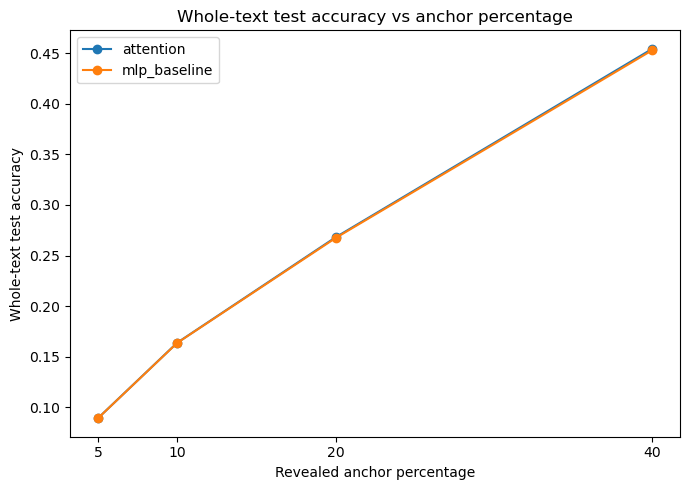

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task5_overall_accuracy.png


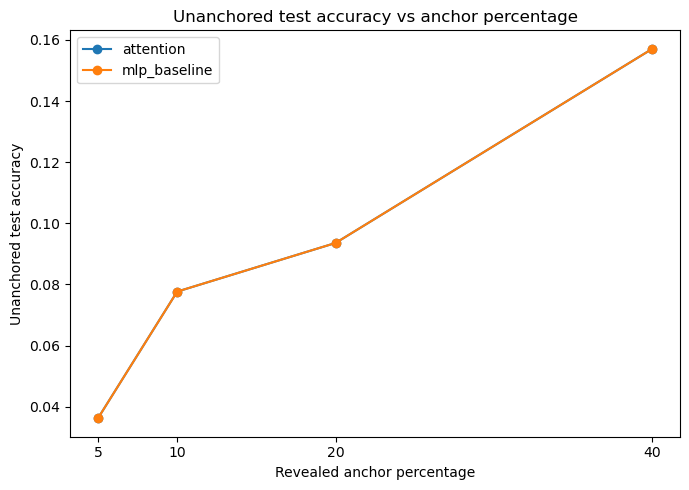

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task5_unanchored_accuracy.png


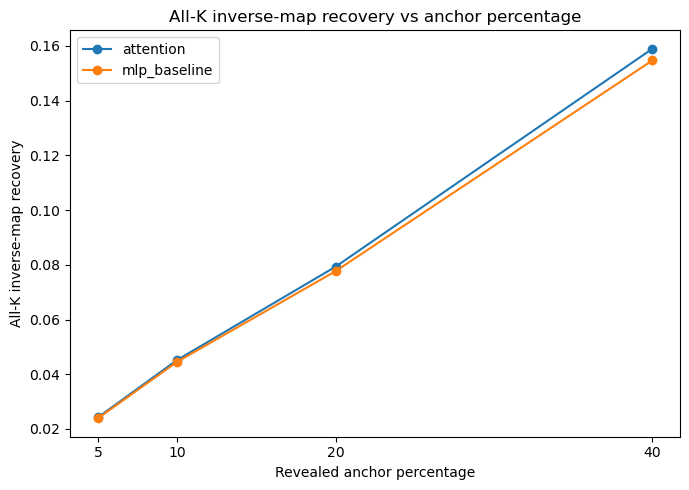

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task5_map_recovery.png


In [15]:
for metric, ylabel, filename in [
    (
        "overall_accuracy",
        "Whole-text test accuracy",
        "task5_overall_accuracy.png",
    ),
    (
        "unanchored_accuracy",
        "Unanchored test accuracy",
        "task5_unanchored_accuracy.png",
    ),
    (
        "all_K_map_recovery",
        "All-K inverse-map recovery",
        "task5_map_recovery.png",
    ),
]:
    plt.figure(
        figsize=(7, 5)
    )

    for model_name in [
        "attention",
        "mlp_baseline",
    ]:
        subset = (
            evaluation_table[
                evaluation_table["model"]
                == model_name
            ]
            .sort_values(
                "anchor_level"
            )
        )

        plt.plot(
            subset[
                "anchor_level"
            ],
            subset[metric],
            marker="o",
            label=model_name,
        )

    plt.xlabel(
        "Revealed anchor percentage"
    )

    plt.ylabel(ylabel)

    plt.title(
        ylabel
        + " vs anchor percentage"
    )

    plt.xticks(
        [5, 10, 20, 40]
    )

    plt.legend()
    plt.tight_layout()

    path = (
        RESULT_DIR
        / filename
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path.resolve())

## Task 6 architecture plots

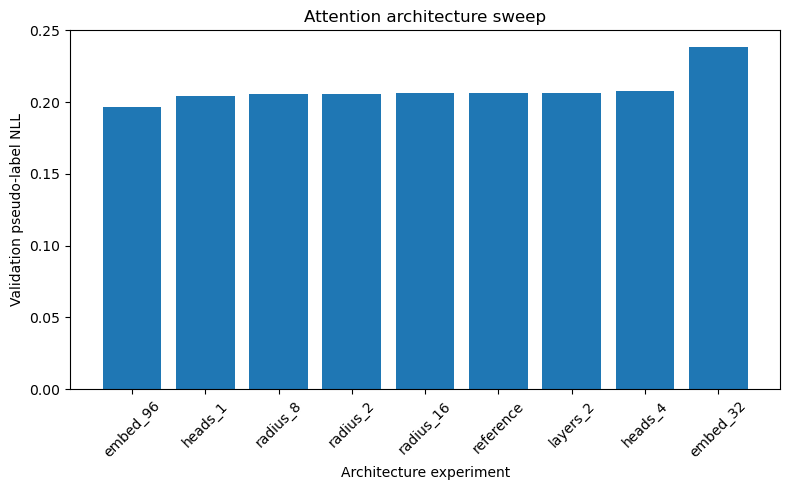

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task6_architecture_validation_nll.png


In [16]:
plt.figure(figsize=(8, 5))

ordered = architecture_results.sort_values(
    "validation_nll"
)

plt.bar(
    ordered["name"],
    ordered["validation_nll"],
)

plt.xlabel("Architecture experiment")
plt.ylabel(
    "Validation pseudo-label NLL"
)
plt.title(
    "Attention architecture sweep"
)
plt.xticks(rotation=45)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task6_architecture_validation_nll.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# Steps 3-6 outputs

### Data

- `task3_id_lookup.csv`
- `task6_architecture_sweep.csv`
- `task6_selected_attention_architecture.json`
- `task3_6_final_training_manifest.csv`
- `task5_bijective_decoder_comparison.csv`
- per-model held-out prediction files

### Models

- architecture-sweep attention checkpoints;
- final attention checkpoints for 5%, 10%, 20%, 40%;
- matched MLP checkpoints for 5%, 10%, 20%, 40%.

### Result images

- whole-text accuracy vs anchors;
- unanchored accuracy vs anchors;
- inverse-map recovery vs anchors;
- architecture validation-NLL comparison.

The next notebook constructs the controlled many-to-one ambiguous-glyph experiment without exposing the original pre-merge glyph identity to the decoder.